# Phân loại Bình luận Spam / Ham trên Mạng Xã hội FB

## Thiết lập Môi trường và Thư viện


In [1]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from underthesea import word_tokenize
from gensim.models import Word2Vec
from sklearn.base import clone
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from scipy.sparse import hstack

pd.set_option('display.max_colwidth', None)
DATA = Path('data')
Path('out').mkdir(exist_ok=True)

/home/peterjohn/miniconda3/envs/ai_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Khám phá Dữ liệu (Exploratory Data Analysis - EDA)


- `01.comments_0_4161.csv`: Raw comments 
- `02.llm_labeled_comments_0_4161.csv`: Dùng LLM với System Prompt đơn giản để gán nhãn toàn bộ
- `03.human_manual_comments_0_1000.csv`: Con người gán nhãn thủ công 1000 mẫu đầu tiên 
- `04.reviewed_comments_0_1000.csv`: So sánh sự sai lệch giữa 1000 mẫu đầu tiên giữa con người và LLM -> Sửa lại System Prompt 
- `05.llm_relabeled_comments_0_4161.csv`: Từ System Prompt mới, dùng LLM gán nhãn lại cho 4161 mẫu

In [2]:
gold = pd.read_csv(DATA / '04.reviewed_comments_0_1000.csv', keep_default_na=False)['label']
old = pd.read_csv(DATA / '02.llm_labeled_comments_0_4161.csv', keep_default_na=False)['label'].iloc[:len(gold)]
new = pd.read_csv(DATA / '05.llm_relabeled_comments_0_4161.csv', keep_default_na=False)['label'].iloc[:len(gold)]
old_error, new_error = (old != gold).mean() * 100, (new != gold).mean() * 100
print(f'LLM cũ sai: {old_error:.2f}% | LLM mới sai: {new_error:.2f}%')
print(f'Chênh lệch (mới - cũ): {new_error - old_error:+.2f} điểm phần trăm')

LLM cũ sai: 4.90% | LLM mới sai: 3.90%
Chênh lệch (mới - cũ): -1.00 điểm phần trăm


### Đọc dữ liệu train và eval

- Train: sử dụng `05.llm_relabeled_comments_0_4161.csv` với 3161 mẫu cuối cùng để train các mô hình ML 
- Test: sử dụng `04.reviewed_comments_0_1000.csv` - 1000 mẫu đã chốt để eval kết quả 

In [3]:
df = pd.read_csv(DATA / '05.llm_relabeled_comments_0_4161.csv', keep_default_na=False).iloc[1000:].copy()
test = pd.read_csv(DATA / '04.reviewed_comments_0_1000.csv', keep_default_na=False)

### Kiểm tra kích thước và kiểu dữ liệu
1. **Dataset Shape**: Số lượng hàng (mẫu) và số lượng cột (thuộc tính).
2. **Non-Null Count**: Kiểm tra giá trị khuyết thiếu (missing values) trên các trường dữ liệu.

In [4]:
print('Dataset Shape:', df.shape)
df.info()

Dataset Shape: (3161, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3161 entries, 1000 to 4160
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   content  3161 non-null   object
 1   label    3161 non-null   object
dtypes: object(2)
memory usage: 49.5+ KB


### Xem một số mẫu dữ liệu ngẫu nhiên

In [5]:
df.head(10)

,content,label
1000,pass mk cuốn triết ạ,ham
1001,Có hint r đó bạn:),ham
1002,Miu lê nhé,ham
1003,nói roi mà nhm chưa nói cụ thể là ai thoi,ham
1004,du thiên với lã phong lâm nhé,ham
1005,"Mời hoàng dũng đi trg, i love ptit",ham
1006,Chi dân nhé,ham
1007,"T đánh nha, t đánh đau lắm nha",ham
1008,à,ham
1009,thấy chưa,ham


### Khảo sát các mẫu bình luận Spam thực tế

In [6]:
df[df["label"]=="spam"].head(5)

,content,label
1012,ID.ZALO.ME,spam
1016,ZENLISHTOEIC.VN,spam
1030,Mình từ tp bắc giang thừa yên sau có ai đi cùng kh,spam
1037,YOUTUBE.COM,spam
1043,"địa chỉ: 262 Thanh Bình, Hà Đông cách PTIT trần phú 1km, cách PTIT ngọc trục 2km",spam


### Thống kê phân bố nhãn (Class Distribution)
* Khảo sát tỷ lệ giữa nhãn `ham` và `spam` để xác định mức độ chênh lệch nhãn của bài toán.

In [7]:
df['label'].value_counts()

label
ham     2702
spam     459
Name: count, dtype: int64

### Trực quan hóa phân bố nhãn bằng biểu đồ cột

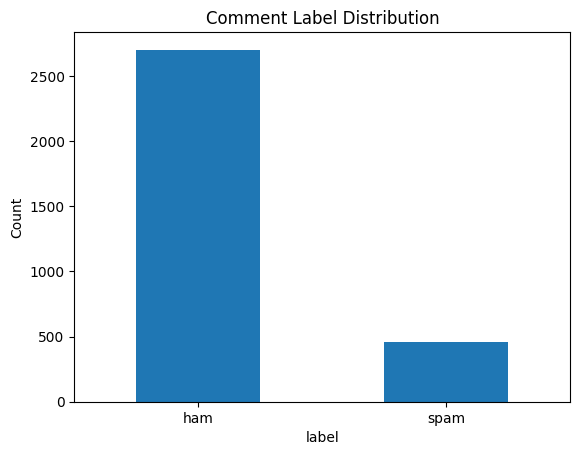

In [8]:
df['label'].value_counts().plot(kind='bar', rot=0)
plt.title('Comment Label Distribution')
plt.ylabel('Count')
plt.show()

### Phân tích độ dài ký tự của bình luận theo nhãn
* **Boxplot**: So sánh phân vị, trung vị và các giá trị ngoại lai (outliers) về độ dài ký tự giữa bình luận bình thường và bình luận spam.

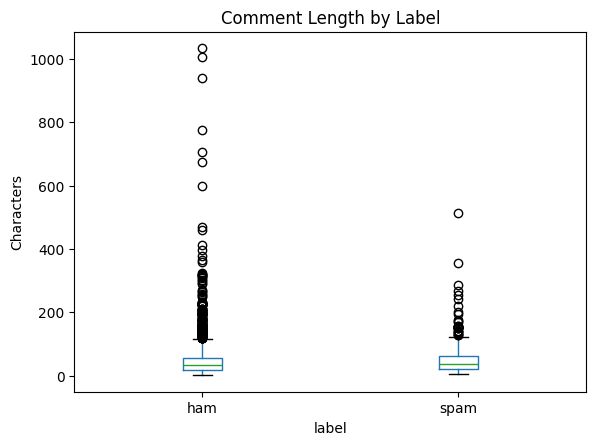

In [9]:
df['char_len'] = df['content'].astype(str).str.len()
df.boxplot(column='char_len', by='label', grid=False)
plt.title('Comment Length by Label')
plt.suptitle('')
plt.ylabel('Characters')
plt.show()

## 2. Tiền Xử Lý Dữ Liệu (Data Preprocessing)
  1. **Chuyển chữ thường (Lowercasing)**: Đồng nhất chữ hoa, chữ thường.
  2. **Tokenization chuyên biệt**: Quy đổi đường link (`token_url`), số điện thoại (`token_sdt`), và từ khóa liên hệ/mời gọi (`token_lienhe` như ib, zalo, sđt) thành các Token đặc trưng đại diện.
  3. **Lọc ký tự đặc biệt**: Giữ lại ký tự chữ và số.
  4. **Tách từ tiếng Việt**: Sử dụng công cụ `underthesea` để ghép các từ ghép (VD: "bán_hàng", "liên_hệ").
  5. **Loại bỏ Stopwords**: Lọc bỏ các từ dừng - từ có tần số cao nhưng ít mang giá trị phân biệt ngữ nghĩa.

### Định nghĩa hàm tiền xử lý văn bản

In [10]:
STOPWORDS = {'là', 'thì', 'và', 'của', 'những', 'các', 'một', 'được', 'với', 'ở', 'này', 'đó', 'cho'}

def preprocess(text):
    text = str(text).lower()
    text = re.sub(r'https?://\S+|www\.\S+', ' token_url ', text)
    text = re.sub(r'(?:(?:\+|00)?84|0)(?:\d[\s\.]?){8,10}\d', ' token_sdt ', text)
    text = re.sub(r'\b(i[\.\s]?b|inbox|inb|zalo|zl|lh|liên hệ)\b', ' token_lienhe ', text)
    text = re.sub(r'[^\w\s]', ' ', text)
    tokens = word_tokenize(text, format='text').split()
    return ' '.join(w for w in tokens if w not in STOPWORDS)

### Áp dụng tiền xử lý lên toàn bộ tập dữ liệu

In [11]:
df['processed'] = df['content'].apply(preprocess)
test['processed'] = test['content'].apply(preprocess)
df[['content', 'processed', 'label']].head(10)

,content,processed,label
1000,pass mk cuốn triết ạ,pass mk cuốn triết ạ,ham
1001,Có hint r đó bạn:),có hint r bạn,ham
1002,Miu lê nhé,miu lê nhé,ham
1003,nói roi mà nhm chưa nói cụ thể là ai thoi,nói roi mà nhm chưa nói cụ_thể ai thoi,ham
1004,du thiên với lã phong lâm nhé,du_thiên lã phong_lâm nhé,ham
1005,"Mời hoàng dũng đi trg, i love ptit",mời hoàng_dũng đi trg i love ptit,ham
1006,Chi dân nhé,chi dân nhé,ham
1007,"T đánh nha, t đánh đau lắm nha",t đánh_nha t đánh đau lắm nha,ham
1008,à,à,ham
1009,thấy chưa,thấy chưa,ham


### Train / Eval

Train trên 3.161 dòng từ vị trí 1000 của 05; eval trên toàn bộ 04. Không chia lại 80/20.

In [12]:
train = df.copy()
pd.DataFrame({'Train': train['label'].value_counts(), 'Eval': test['label'].value_counts()})

,Train,Eval
label,,
ham,2702,860
spam,459,140


## 3. Trích Xuất Đặc Trưng & Biểu Diễn Vector (Feature Engineering)
* Nghiên cứu so sánh 5 không gian biểu diễn đặc trưng văn bản khác nhau:
  1. **Bag of Words (BoW)**: Biểu diễn tần số xuất hiện từ và cụm từ (1-gram, 2-gram).
  2. **TF-IDF**: Trọng số hóa tần số từ theo nghịch đảo tần số văn bản.
  3. **Word2Vec Averaging**: Biểu diễn ngữ nghĩa phân tán (dense semantic embedding) bằng trung bình cộng vector từ.
  4. **Word2Vec TF-IDF Weighted**: Trung bình có trọng số IDF nhằm ưu tiên các từ mang tính đặc thù cao hơn.
  5. **Hybrid (TF-IDF + Word2Vec)**: Kết hợp vector n-gram thưa và vector ngữ nghĩa đặc bằng phép ghép nối (concatenation/hstack).

### Mô hình Bag-of-Words (BoW / N-gram Count)
* Cấu hình: `ngram_range=(1, 2)` (kết hợp cả unigram và bigram), loại bỏ các từ chỉ xuất hiện 1 lần (`min_df=2`).

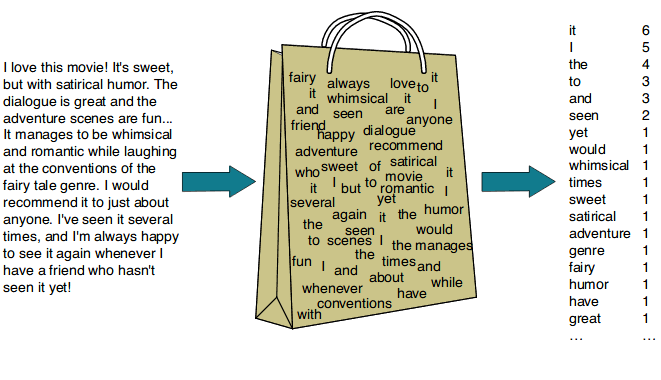

In [13]:
vec_bow = CountVectorizer(ngram_range=(1, 2), min_df=2)
X_train_bow = vec_bow.fit_transform(train['processed'])
X_test_bow = vec_bow.transform(test['processed'])
print('BoW Vocabulary Size:', X_train_bow.shape[1])

BoW Vocabulary Size: 4412


### Khảo sát danh sách đặc trưng BoW

In [14]:
feature_names = vec_bow.get_feature_names_out()
print("100 đặc trưng đầu:")
print(feature_names[:100])
print("\n100 đặc trưng cuối:")
print(feature_names[-100:])

100 đặc trưng đầu:
['000' '000 người' '000 tháng' '07' '08' '08 2026' '09' '09 2026' '10'
 '10 20' '10 em' '10 học' '10 ra' '10 tr' '10 vào' '10 điểm' '100'
 '100 000' '100 phòng' '100 size' '103' '11' '12' '120' '128' '13' '14'
 '14 tín' '145' '15' '150' '16' '17' '18' '18 tuổi' '19' '19 e04' '20'
 '20 người' '200' '200 câu' '200 người' '2024' '2025' '2026' '2027' '21'
 '216' '22' '220' '223' '225' '225 990' '23' '24' '25' '250' '255'
 '255 nguyễn_văn_trỗi' '26' '27' '28' '30' '30 nha' '30 nhé' '300' '305'
 '316' '319' '336' '35' '35 khối' '36' '40' '40 câu' '40 người' '43' '450'
 '50' '500' '542' '60' '600' '601' '70' '700' '730' '730 toeic' '730 đổi'
 '80' '864' '88' '90' '90 nhé' '924' '95' '981' '990' '993' '993 dạ']

100 đặc trưng cuối:
['đọc nếu' 'đỏ' 'đỏ ptit' 'đối' 'đối_ngoại' 'đối_ngoại mpc' 'đối_nội'
 'đối_nội gen' 'đối_nội sẽ' 'đối_với' 'đồ' 'đồ cơ_bản' 'đồ mà'
 'đồ thể_thao' 'đồ vào' 'đồ_án' 'đồng' 'đồng thân_thiện' 'đổ' 'đổi'
 'đổi chỗ' 'đổi full' 'đổi học' 'đổi đc' 'đổi 

### Trích xuất mẫu vector BoW của 1 bình luận

In [15]:
print("Raw:", train.iloc[36]["content"])
print("Processed:", train.iloc[36]["processed"])
print("Vector BoW:", X_train_bow[36].toarray())
np.savetxt("out/vector_bow.txt", X_train_bow[36].toarray().ravel(), fmt="%.6f")
print("Shape:", X_train_bow[36].shape)

Raw: mục nào vậy ạ, phải 1.4 ko ạ tại 1.4 em full mất r
Processed: mục nào vậy ạ phải 1 4 ko ạ tại 1 4 em full mất r
Vector BoW: [[0 0 0 ... 0 0 0]]
Shape: (1, 4412)


### Mô hình TF-IDF (Term Frequency - Inverse Document Frequency)
* Cấu hình: `ngram_range=(1, 2)`, `min_df=2`, bật `sublinear_tf=True` (thay thế $tf$ bằng $1 + \log(tf)$) giúp làm dịu ảnh hưởng của các từ lặp lại nhiều lần.

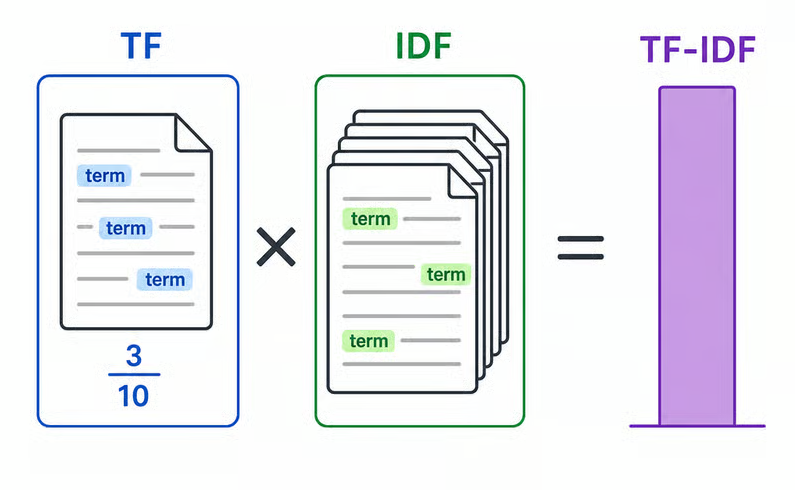

In [16]:
vec_tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train_tfidf = vec_tfidf.fit_transform(train['processed'])
X_test_tfidf = vec_tfidf.transform(test['processed'])
print('TF-IDF Features Size:', X_train_tfidf.shape[1])

TF-IDF Features Size: 4412


### Khảo sát danh sách đặc trưng TF-IDF

In [17]:
feature_names = vec_tfidf.get_feature_names_out()
print("100 đặc trưng đầu:", feature_names[:100])
print("100 đặc trưng cuối:", feature_names[-100:])

100 đặc trưng đầu: ['000' '000 người' '000 tháng' '07' '08' '08 2026' '09' '09 2026' '10'
 '10 20' '10 em' '10 học' '10 ra' '10 tr' '10 vào' '10 điểm' '100'
 '100 000' '100 phòng' '100 size' '103' '11' '12' '120' '128' '13' '14'
 '14 tín' '145' '15' '150' '16' '17' '18' '18 tuổi' '19' '19 e04' '20'
 '20 người' '200' '200 câu' '200 người' '2024' '2025' '2026' '2027' '21'
 '216' '22' '220' '223' '225' '225 990' '23' '24' '25' '250' '255'
 '255 nguyễn_văn_trỗi' '26' '27' '28' '30' '30 nha' '30 nhé' '300' '305'
 '316' '319' '336' '35' '35 khối' '36' '40' '40 câu' '40 người' '43' '450'
 '50' '500' '542' '60' '600' '601' '70' '700' '730' '730 toeic' '730 đổi'
 '80' '864' '88' '90' '90 nhé' '924' '95' '981' '990' '993' '993 dạ']
100 đặc trưng cuối: ['đọc nếu' 'đỏ' 'đỏ ptit' 'đối' 'đối_ngoại' 'đối_ngoại mpc' 'đối_nội'
 'đối_nội gen' 'đối_nội sẽ' 'đối_với' 'đồ' 'đồ cơ_bản' 'đồ mà'
 'đồ thể_thao' 'đồ vào' 'đồ_án' 'đồng' 'đồng thân_thiện' 'đổ' 'đổi'
 'đổi chỗ' 'đổi full' 'đổi học' 'đổi đc' 'đổi đ

### Trích xuất mẫu vector TF-IDF của 1 bình luận

In [18]:
print("Raw:", train.iloc[36]["content"])
print("Processed:", train.iloc[36]["processed"])
print("Vector TF-IDF:", X_train_tfidf[36].toarray())
np.savetxt("out/vector_tfidf.txt", X_train_tfidf[36].toarray().ravel(), fmt="%.6f")
print("Shape:", X_train_tfidf[36].shape)

Raw: mục nào vậy ạ, phải 1.4 ko ạ tại 1.4 em full mất r
Processed: mục nào vậy ạ phải 1 4 ko ạ tại 1 4 em full mất r
Vector TF-IDF: [[0. 0. 0. ... 0. 0. 0.]]
Shape: (1, 4412)


### Huấn luyện mô hình nhúng từ Word2Vec (Continuous Skip-gram / CBOW)
1. **vector_size=100**: Kích thước chiều không gian embedding của mỗi từ.
2. **window=5**: Kích thước cửa sổ ngữ cảnh xung quanh từ mục tiêu.
3. **epochs=50**: Số lượt duyệt qua tập ngữ liệu train.

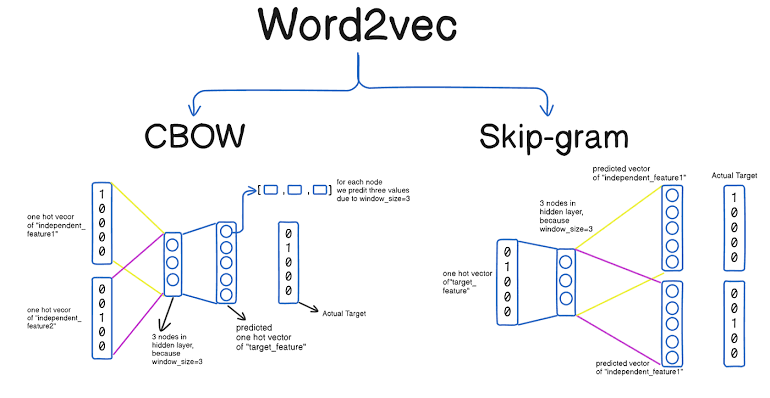

In [19]:
sentences = [s.split() for s in train['processed']]
w2v_model = Word2Vec(sentences, vector_size=100, window=5, min_count=1, workers=1, epochs=50, seed=42)
print('Word2Vec Vocabulary Size:', len(w2v_model.wv))

Word2Vec Vocabulary Size: 4495


### Khảo sát từ vựng đã học trong mô hình Word2Vec

In [20]:
print("100 từ đầu:", w2v_model.wv.index_to_key[:100])
print("100 từ cuối:", w2v_model.wv.index_to_key[-100:])

100 từ đầu: ['có', 'em', 'mình', 'ạ', 'học', 'đi', '1', 'bạn', 'k', 'nhé', 'b', 'token_lienhe', '2', 'mà', 'để', 'ko', 'không', 'e', 'còn', 'đc', 'người', 'vào', 'nha', 'cũng', 'trường', 'thôi', 'lại', 'nào', '3', 'đâu', 'phải', 'rồi', 'cần', 'tham_gia', 'thi', 'hay', 'anh', 'nên', 'ơi', 'token_sdt', 'cái', 'lên', 'sẽ', 'clb', 'mấy', 'xin', 'gì', 'nếu', 'nhiều', 'năm', 'điểm', 'chưa', 'cứ', 'làm', 'r', 'ra', 'thấy', 'ai', 'luôn', '4', 'mới', 'ptit', 'đang', 'ẩn_danh', 'aptis', 'đến', 'phòng', 'trong', 'đấy', 'chỉ', 'sau', 'như', 'về', 'đã', 'sao', 'qua', 'có_thể', 'pass', 'vậy', 'vẫn', 'từ', 'đây', 'cô', 'muốn', '5', 'hơn', 'cả', 'c', 'xem', 'lấy', 'trên', 'tìm', 'nữa', 'chị', 'tôi', 'tiền', 'tháng', 'mất', 'nhưng', 'chứ']
100 từ cuối: ['tềnh_êu', 'câu_chuyện', 'nhặc', 'giả_vờ', 'off', 'live', '299', 'gi', '377', 'chắc_sinh', 'đề_test', 'câu_cơ', 'vợ', 'ưa', 'kì_học', 'tr1tin', '66668888', '123456789', 'zái', 'hòn', 'dtd', 'siêu_yêu', 'cky', 'gãi', 'cân', 'trloi', 'luồng', 'lệnh', 'fro

### Minh họa vector embedding của 1 từ cụ thể

In [21]:
word = w2v_model.wv.index_to_key[36]
print("Từ:", word)
print("Vector:", w2v_model.wv[word])
print("Shape:", w2v_model.wv[word].shape)


Từ: anh
Vector: [ 0.05667772  1.1628073  -1.7602665   0.46122593  1.5922464   0.04805809
 -0.25638506  0.1889847  -0.11842985 -0.09628796 -0.82078713  0.50468725
  1.7851946  -0.33298877  0.2853184  -0.46996054 -0.62726384 -1.1742973
 -0.444344   -1.0843084   2.180383   -0.2789298   0.30866882 -0.7999969
  0.5049208   0.3561718   0.43603507  1.0844699   0.43729264  0.54957724
 -0.28743902 -0.5298643  -0.6147345   0.81626904  1.2400717  -0.05204931
 -0.7916116  -0.4882437  -2.5426927   0.2926193  -0.03287336  0.02304722
  1.3668936  -0.25138515  1.8738861   0.3010725  -0.11611836  0.74997264
  1.784776    0.30843797  0.6836238  -2.1528635  -0.32258946 -0.6220364
  0.46179038 -1.1134795   0.16124602  1.7047856   0.606698    0.7611051
  0.21203186 -1.0285852   1.4728749   1.7803606   0.7197497   0.5992314
  0.03572596 -0.72198194  0.16809444 -0.86226404 -2.0895605  -1.6720812
  0.6096158  -0.9734998   2.067261   -0.24985717 -0.9647535   1.1219002
 -0.1284896   0.63921404  1.0860196  -1.63

### Biểu diễn bình luận bằng trung bình cộng vector từ (Word2Vec Average Pooling)
* Vector đại diện của cả bình luận được tính bằng:
  $$\mathbf{d}_{avg} = \frac{1}{|V_d|} \sum_{w \in V_d} \mathbf{v}_w$$

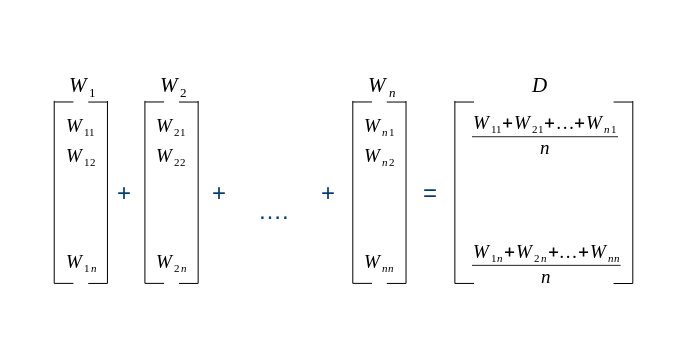

In [22]:
def doc_vector_avg(tokens):
    vecs = [w2v_model.wv[w] for w in tokens if w in w2v_model.wv]
    return np.mean(vecs, axis=0) if len(vecs) > 0 else np.zeros(w2v_model.vector_size)

X_train_w2v_avg = np.array([doc_vector_avg(s.split()) for s in train['processed']])
X_test_w2v_avg = np.array([doc_vector_avg(s.split()) for s in test['processed']])

### Trích xuất mẫu vector Word2Vec Average

In [23]:
print("Processed:", train.iloc[36]["processed"])
print("Vector Word2Vec Avg:", X_train_w2v_avg[36])
print("Shape:", X_train_w2v_avg[36].shape)
np.savetxt("out/vector_w2v_avg.txt", X_train_w2v_avg[36], fmt="%.6f")

Processed: mục nào vậy ạ phải 1 4 ko ạ tại 1 4 em full mất r
Vector Word2Vec Avg: [ 0.54491305  0.19209661 -0.43715444  0.43135867 -0.03142346  0.40101942
 -0.02747291  0.47535527 -0.15639228 -0.30810815 -0.59854847  0.02696805
  0.33005455  0.57345361 -0.43803728 -0.39276281  0.14792091 -1.12961662
 -0.21725111  0.14434379  0.02504554  0.64973682  0.15228246  0.46844336
  0.26240447 -0.33948597 -0.53097135  0.69071102 -0.71200401 -0.61208528
  0.29770875 -0.36708257 -0.00168752 -0.28721881  0.38050026 -0.59888214
 -0.09698588 -0.25543934 -0.00230958  0.25247359 -0.25814193  0.02892753
  0.75081378 -0.49863541  0.45563963 -0.33143377  0.36912495  0.52403963
  0.68618077 -0.17471562 -0.05102519 -0.57206345  0.14274979 -0.11533058
  0.02660596 -0.7461518   0.14992583  0.18101208  0.22832596  1.04442883
 -0.46582797 -0.39824015 -0.35625866  0.3733882   0.54384464 -0.55119139
  0.09402584 -0.02748246  0.02048475 -0.44547167 -0.72987431 -0.46183851
  0.15941581 -0.38184017  0.81934708  0.33

### Biểu diễn bình luận bằng Word2Vec có trọng số TF-IDF (IDF-Weighted Pooling)
* Trọng số hóa IDF nhằm gán mức độ quan trọng cao hơn cho các từ khóa mang tính phân biệt:
  $$\mathbf{d}_{weighted} = \frac{\sum_{w \in V_d} idf(w) \cdot \mathbf{v}_w}{\sum_{w \in V_d} idf(w)}$$

In [24]:
tfidf_uni = TfidfVectorizer(ngram_range=(1, 1), min_df=1)
tfidf_uni.fit(train['processed'])
idf_dict = dict(zip(tfidf_uni.get_feature_names_out(), tfidf_uni.idf_))

def doc_vector_tfidf_avg(tokens):
    vecs, weights = [], []
    for w in tokens:
        if w in w2v_model.wv:
            weight = idf_dict.get(w, 1.0)
            vecs.append(w2v_model.wv[w] * weight)
            weights.append(weight)
    return np.sum(vecs, axis=0) / sum(weights) if (len(vecs) > 0 and sum(weights) > 0) else np.zeros(w2v_model.vector_size)

X_train_w2v_tfidf = np.array([doc_vector_tfidf_avg(s.split()) for s in train['processed']])
X_test_w2v_tfidf = np.array([doc_vector_tfidf_avg(s.split()) for s in test['processed']])


### Minh họa trọng số IDF của các từ trong một bình luận mẫu

In [25]:
for w in train.iloc[36]["processed"].split():
    if w in w2v_model.wv:
        print(f"{w}: {idf_dict.get(w, 1.0):.4f}")

mục: 6.9795
nào: 4.2148
vậy: 4.7963
ạ: 1.0000
phải: 4.2883
1: 1.0000
4: 1.0000
ko: 3.9057
ạ: 1.0000
tại: 5.9235
1: 1.0000
4: 1.0000
em: 3.2359
full: 5.4480
mất: 5.0159
r: 1.0000


### Trích xuất mẫu vector Word2Vec có trọng số IDF

In [26]:
print("Vector Word2Vec có trọng số:", X_train_w2v_tfidf[36])
print("Shape:", X_train_w2v_tfidf[36].shape)
np.savetxt("out/vector_w2v_weighted.txt", X_train_w2v_tfidf[36], fmt="%.6f")

Vector Word2Vec có trọng số: [ 3.65853181e-01  1.41402630e-01 -4.71012306e-01  3.24624588e-01
 -2.35889910e-02  3.05833061e-01 -2.59225648e-02  3.36667785e-01
 -2.75519245e-01 -4.16308408e-01 -6.35783001e-01  1.12897648e-01
  3.96823716e-01  5.38927188e-01 -3.63527071e-01 -2.41037933e-01
  1.14475947e-01 -1.13193374e+00 -1.65571492e-01  7.80012745e-02
  6.06644443e-02  4.39078113e-01  1.77720422e-01  4.13605837e-01
  1.94729716e-01 -2.56248135e-01 -3.15253578e-01  5.45490172e-01
 -4.16644128e-01 -5.59948509e-01  1.15026099e-01 -3.95701390e-01
  8.23339850e-02 -2.58320641e-01  4.07331329e-01 -5.78862706e-01
 -6.02008425e-02 -3.16679486e-01 -1.65169636e-02  2.66038047e-01
 -6.66071910e-02 -1.36879639e-01  6.89521363e-01 -5.59567978e-01
  3.74740680e-01 -3.00297163e-01  2.44401250e-01  5.14630023e-01
  7.01900971e-01 -3.07730771e-01  4.12292770e-02 -6.71634092e-01
  2.39373547e-01 -1.09665103e-01 -1.11119510e-01 -5.50965840e-01
  1.48594760e-01  1.55978002e-01  3.07087711e-01  9.35354394e

### Không gian đặc trưng kết hợp Hybrid (TF-IDF + Word2Vec)
* Ghép nối (concatenate) vector thưa TF-IDF n-gram và vector đặc Word2Vec thành vector đa góc nhìn:
  $$\mathbf{X}_{hybrid} = [\mathbf{X}_{TF-IDF} \,\|\, \mathbf{X}_{W2V\_TFIDF}]$$

In [27]:
X_train_combined = hstack([X_train_tfidf, X_train_w2v_tfidf]).tocsr()
X_test_combined = hstack([X_test_tfidf, X_test_w2v_tfidf]).tocsr()
print('Hybrid Features Size:', X_train_combined.shape[1])

Hybrid Features Size: 4512


## 4. Huấn Luyện Mô Hình (Model Training)
* Khởi tạo các thuật toán học máy phân loại văn bản:
  1. **MultinomialNB (Multinomial Naive Bayes)**: Phù hợp với đặc trưng tần số đếm rời rạc (BoW, TF-IDF).
  <br>
  <img src="https://databasecamp.de/wp-content/uploads/naive-bayes-overview-1024x709.png" width="400" />
  
  2. **LinearSVC (Linear Support Vector Classifier)**: Tối ưu cho không gian đặc trưng nhiều chiều, sử dụng tham số `class_weight='balanced'` để tự động điều chỉnh trọng số bù đắp hiện tượng mất cân bằng lớp (data imbalance).
  <br>
  <img src="https://machinelearningcoban.com/assets/19_svm/svm3.png" width="400" />

In [28]:
multinomialNB = MultinomialNB()
linearSVC = LinearSVC(
    dual='auto', class_weight='balanced',
    C=1.0, max_iter=3000, random_state=42
)

### Huấn luyện các tổ hợp đặc trưng và mô hình

In [29]:
experiments = {
    ('BoW', 'MultinomialNB'): (X_train_bow, X_test_bow, multinomialNB),
    ('BoW', 'LinearSVC'): (X_train_bow, X_test_bow, linearSVC),
    ('TF-IDF', 'MultinomialNB'): (X_train_tfidf, X_test_tfidf, multinomialNB),
    ('TF-IDF', 'LinearSVC'): (X_train_tfidf, X_test_tfidf, linearSVC),
    ('Word2Vec Avg', 'LinearSVC'): (X_train_w2v_avg, X_test_w2v_avg, linearSVC),
    ('Word2Vec TF-IDF Avg', 'LinearSVC'): (X_train_w2v_tfidf, X_test_w2v_tfidf, linearSVC),
    ('TF-IDF + Word2Vec', 'LinearSVC'): (X_train_combined, X_test_combined, linearSVC),
}

results = []
predictions = {}
for (feat, algo), (X_tr, X_te, estimator) in experiments.items():
    clf = clone(estimator)
    clf.fit(X_tr, train['label'])
    y_pred = clf.predict(X_te)
    predictions[(feat, algo)] = y_pred
    results.append({
        'Feature': feat,
        'Model': algo,
        'Accuracy': accuracy_score(test['label'], y_pred),
        'Precision macro': precision_score(test['label'], y_pred, average='macro', zero_division=0),
        'Recall macro': recall_score(test['label'], y_pred, average='macro', zero_division=0),
        'Precision spam': precision_score(test['label'], y_pred, pos_label='spam', zero_division=0),
        'Recall spam': recall_score(test['label'], y_pred, pos_label='spam', zero_division=0),
        'F1 spam': f1_score(test['label'], y_pred, pos_label='spam', zero_division=0),
        'Macro F1': f1_score(test['label'], y_pred, average='macro', zero_division=0),
    })

## 5. Đánh giá mô hình trên toàn bộ 04

Báo cáo Accuracy, Precision / Recall / F1 của spam, Macro F1 và confusion matrix.
Giữ nguyên cấu hình mô hình khi đánh giá trên 04.

In [30]:
scores_df = pd.DataFrame(results)
scores_df

,Feature,Model,Accuracy,Precision macro,Recall macro,Precision spam,Recall spam,F1 spam,Macro F1
0,BoW,MultinomialNB,0.926,0.854250,0.828405,0.757812,0.692857,0.723881,0.840578
1,BoW,LinearSVC,0.909,0.811416,0.809551,0.676259,0.671429,0.673835,0.810479
2,TF-IDF,MultinomialNB,0.899,0.891124,0.657226,0.882353,0.321429,0.471204,0.707686
3,TF-IDF,LinearSVC,0.910,0.813123,0.813123,0.678571,0.678571,0.678571,0.813123
4,Word2Vec Avg,LinearSVC,0.878,0.752104,0.827409,0.546392,0.757143,0.634731,0.780751
5,Word2Vec TF-IDF Avg,LinearSVC,0.868,0.737500,0.815615,0.520000,0.742857,0.611765,0.766123
6,TF-IDF + Word2Vec,LinearSVC,0.911,0.817277,0.807724,0.688889,0.664286,0.676364,0.812385


### Trực quan hóa so sánh Macro F1 giữa các cấu hình

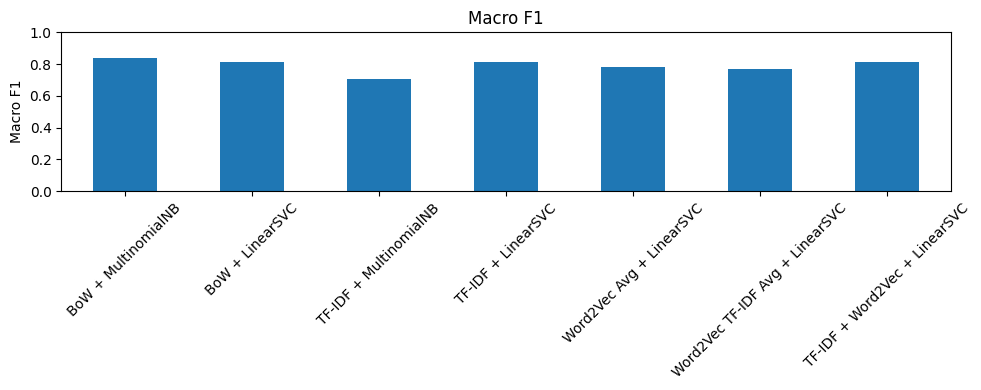

In [31]:
model_names = scores_df['Feature'] + ' + ' + scores_df['Model']
scores_df.set_index(model_names)['Macro F1'].plot(kind='bar', figsize=(10, 4), rot=45)
plt.title('Macro F1')
plt.ylabel('Macro F1')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

### Đánh giá chi tiết BoW + MultinomialNB

In [32]:
selected_model = ('BoW', 'MultinomialNB')
print('Cấu hình báo cáo chi tiết:', selected_model)

Cấu hình báo cáo chi tiết: ('BoW', 'MultinomialNB')


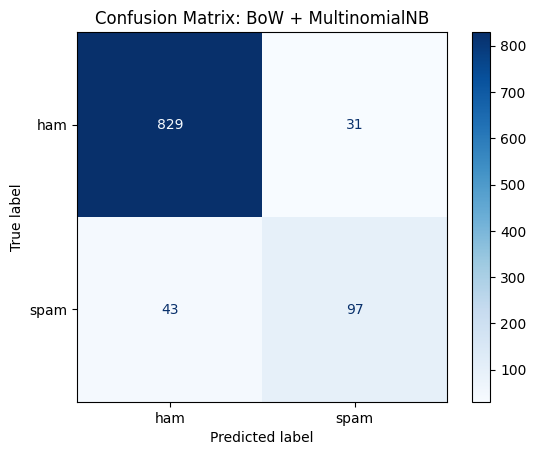

In [33]:
cm = confusion_matrix(test['label'], predictions[selected_model], labels=['ham', 'spam'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['ham', 'spam'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix: ' + ' + '.join(selected_model))
plt.show()

* **Báo cáo phân loại chi tiết (Classification Report)**:

In [34]:
print(classification_report(test['label'], predictions[selected_model], digits=4, zero_division=0))

              precision    recall  f1-score   support

         ham     0.9507    0.9640    0.9573       860
        spam     0.7578    0.6929    0.7239       140

    accuracy                         0.9260      1000
   macro avg     0.8543    0.8284    0.8406      1000
weighted avg     0.9237    0.9260    0.9246      1000



### Phân tích lỗi sau đánh giá

In [35]:
review = test[['content', 'label']].copy()
review['pred'] = predictions[selected_model]
review[review['label'] != review['pred']].head(10)

,content,label,pred
5,@nêu bật à tui còn có cả cuốn Kinh tế lượng nữa ạ. Các bé vô quẹo lựa nha,spam,ham
14,c có áo polo size M 60k nha,ham,spam
18,b đưa sđt đây,spam,ham
54,"Lộ trình rõ ràng, có chiến lược từng kỹ năng",ham,spam
73,b có phòng ch b,ham,spam
88,"mình nhận nhé, lấy 15k thôi",spam,ham
95,qua chỗ Ao Sen tìm đi e :))) Có dán sđt đấy,spam,ham
109,Mk pass 2 bộ TD nha,ham,spam
110,Mình pass bomber size M ạ,ham,spam
161,theo giá in ở Ao sen + 5k=)),spam,ham


### Lưu bảng kết quả

In [36]:
scores_df.to_csv('out/model_scores.csv', index=False, encoding='utf-8-sig')
print('Đã lưu out/model_scores.csv')

Đã lưu out/model_scores.csv
